# ML Workflow

  Dataset
    →
  Understand columns
    →
  Clean data
    →
  Handle missing values
    →
  EDA
    →
  Identify target column
    →
  Separate X and y
    →
  Encode categorical columns
    →
  Train/Test Split
    →
  Feature Scaling (if required)
    →
  Train ML model
    →
  Prediction
    →
  Evaluate model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_table("/content/Real estate.csv",sep = ",")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [4]:
df.drop('No',axis=1,inplace=True)

In [5]:
df.rename(columns={
    'X1 transaction date': 'transaction_date',
    'X2 house age': 'house_age',
    'X3 distance to the nearest MRT station': 'distance_to_mrt',
    'X4 number of convenience stores': 'num_convenience_stores',
    'X5 latitude': 'latitude',
    'X6 longitude': 'longitude',
    'Y house price of unit area': 'house_price_unit_area'
}, inplace=True)

In [6]:
df.head()

,transaction_date,house_age,distance_to_mrt,num_convenience_stores,latitude,longitude,house_price_unit_area
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   transaction_date        414 non-null    float64
 1   house_age               414 non-null    float64
 2   distance_to_mrt         414 non-null    float64
 3   num_convenience_stores  414 non-null    int64  
 4   latitude                414 non-null    float64
 5   longitude               414 non-null    float64
 6   house_price_unit_area   414 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 22.8 KB


In [8]:
df.describe()

,transaction_date,house_age,distance_to_mrt,num_convenience_stores,latitude,longitude,house_price_unit_area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


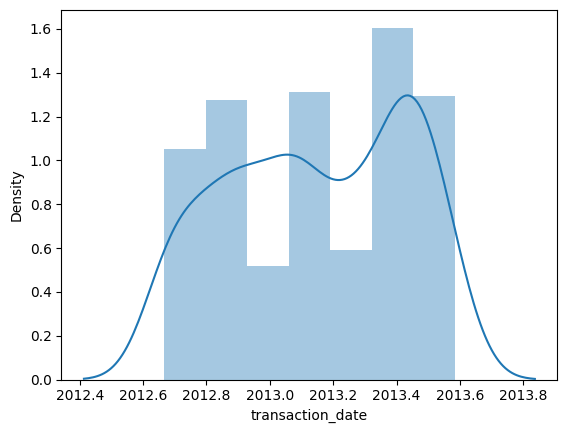

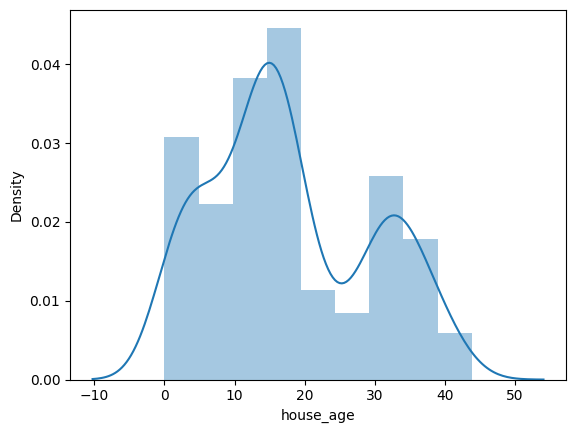

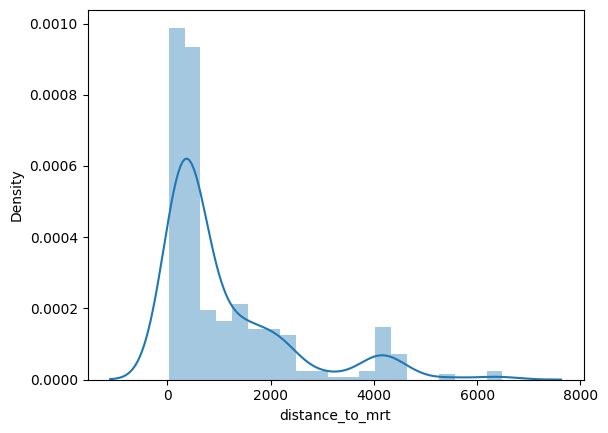

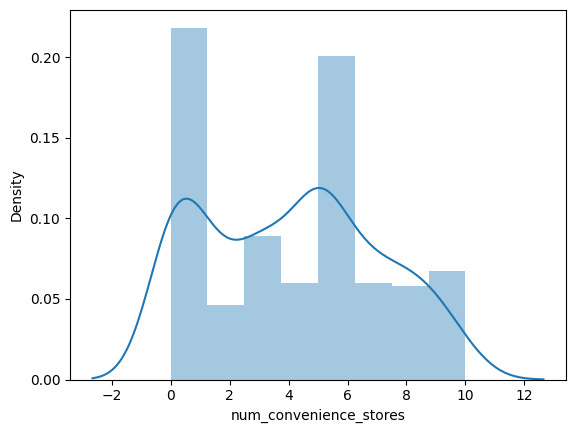

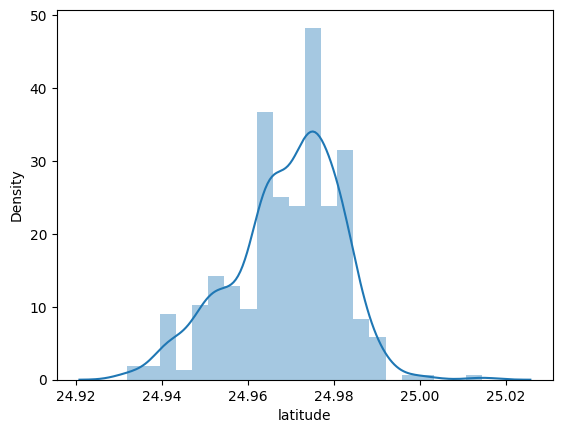

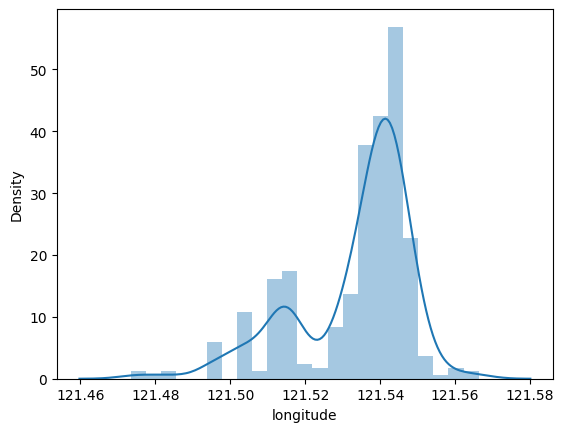

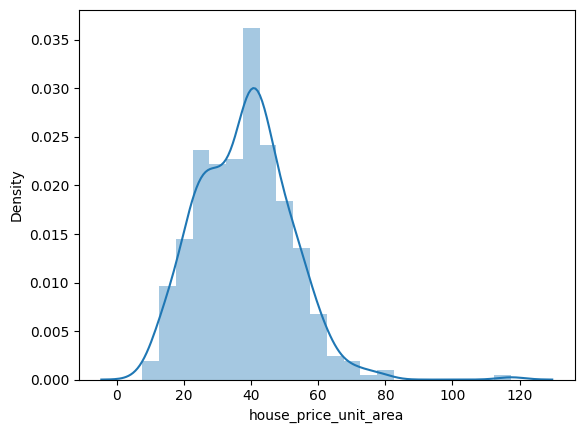

In [9]:
for i in df.columns:
  sns.distplot(df[i])
  plt.show()

<Axes: >

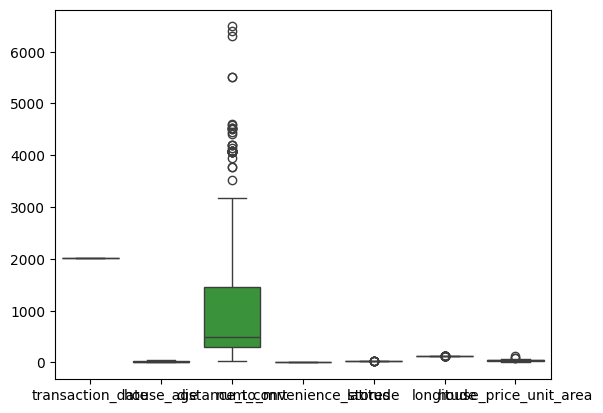

In [10]:
sns.boxplot(df)

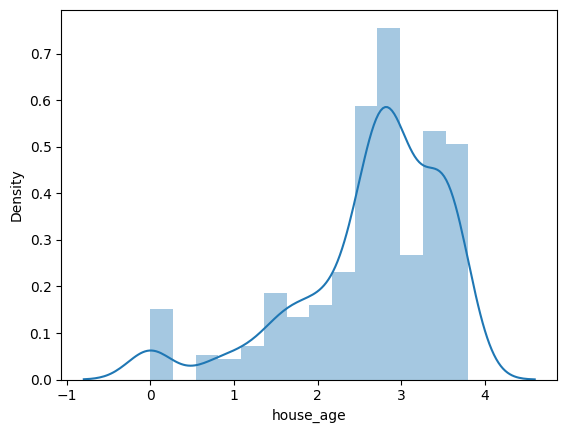

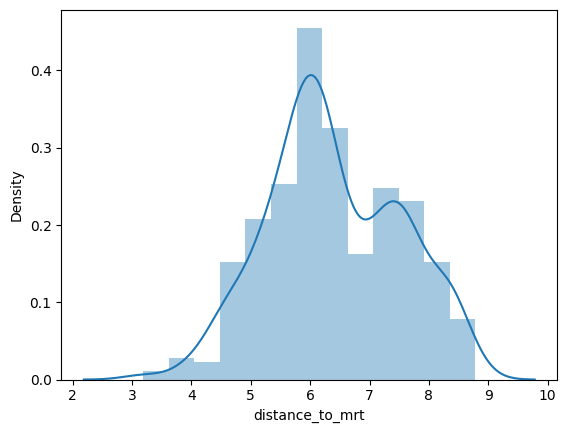

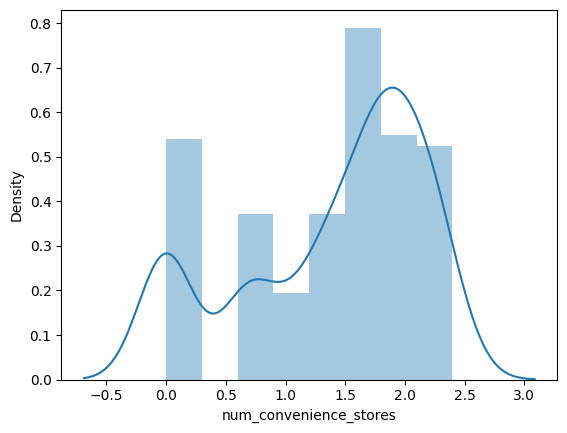

In [11]:
skew = ['house_age', 'distance_to_mrt', 'num_convenience_stores']
for i in skew:
  # Use np.log1p to handle 0 values safely (calculates log(1 + x))
  df[i] = np.log1p(df[i])
  sns.distplot(df[i])
  plt.show()

<Axes: >

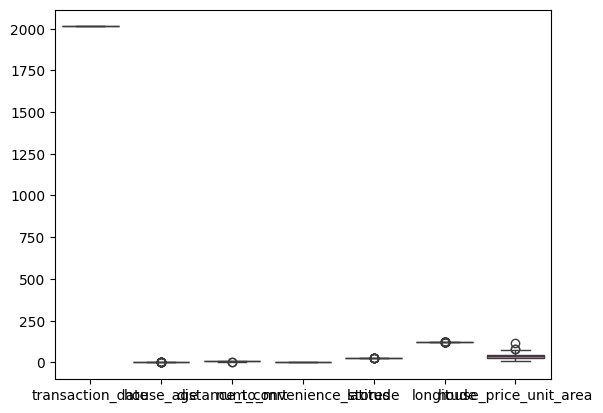

In [12]:
sns.boxplot(df)

In [13]:
df.describe()

,transaction_date,house_age,distance_to_mrt,num_convenience_stores,latitude,longitude,house_price_unit_area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,2013.148971,2.650876,6.394739,1.391022,24.969030,121.533361,37.980193
std,0.281967,0.882541,1.116584,0.766790,0.012410,0.015347,13.606488
min,2012.667000,0.000000,3.193880,0.000000,24.932070,121.473530,7.600000
25%,2012.917000,2.305073,5.671000,0.693147,24.963000,121.528085,27.700000
50%,2013.167000,2.839078,6.200978,1.609438,24.971100,121.538630,38.450000
75%,2013.417000,3.372450,7.282951,1.945910,24.977455,121.543305,46.600000
max,2013.583000,3.802208,8.777867,2.397895,25.014590,121.566270,117.500000


In [14]:
X=df.iloc[ : , :-1]
y=df.iloc[ : ,-1]

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [16]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

In [17]:
def Poly_model(model):
  X_train_pf = model.fit_transform(X_train)
  X_test_pf = model.transform(X_test)
  from sklearn.linear_model import LinearRegression
  poly_lr = LinearRegression()
  poly_lr.fit(X_train_pf, y_train)
  y_pred = poly_lr.predict(X_test_pf)
  train_score = poly_lr.score(X_train_pf, y_train)
  test_score = poly_lr.score(X_test_pf, y_test)
  from sklearn.metrics import r2_score
  print("R2 Score:", r2_score(y_test, y_pred))
  print()
  print("Train Score:", train_score)
  print("Test Score:", test_score)
  print()
  chart(y_test,y_pred)
  return poly_lr

In [18]:
def evaluate_model(model):
  model.fit(X_train,y_train)
  y_pred=model.predict(X_test)
  train_score = model.score(X_train, y_train)
  test_score = model.score(X_test, y_test)
  from sklearn.metrics import r2_score
  print("R2 Score:", r2_score(y_test, y_pred))
  print()
  print("Train Score:", train_score)
  print("Test Score:", test_score)
  print()
  chart(y_test,y_pred)
  return model

In [19]:
def chart(y_test,y_pred):
  # Plot actual vs predicted values (both are 1D arrays of length 83)
  plt.scatter(y_test, y_pred, color="red", alpha=0.6)
  plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="blue", lw=2)
  plt.xlabel("Actual Values")
  plt.ylabel("Predicted Values")
  plt.title("Actual vs Predicted")
  plt.show()
  print()

R2 Score: 0.7297727335945353

Train Score: 0.6491411122117674
Test Score: 0.7297727335945353



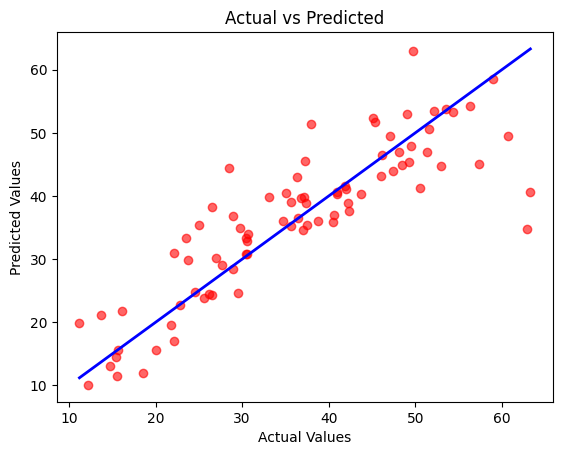

In [20]:
from sklearn.linear_model import LinearRegression
lr=evaluate_model(LinearRegression())

R2 Score: 0.7545588762890063

Train Score: 0.6981280857402136
Test Score: 0.7545588762890063



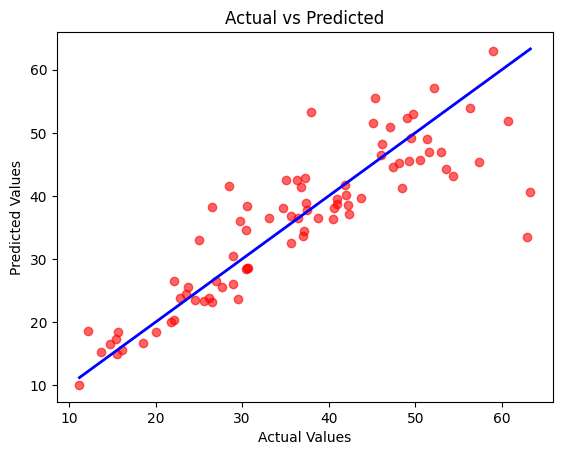

In [26]:
from sklearn.preprocessing import PolynomialFeatures
lr = Poly_model(PolynomialFeatures(degree=2))

R2 Score: 0.7298440607776168

Train Score: 0.649141046407743
Test Score: 0.7298440607776168



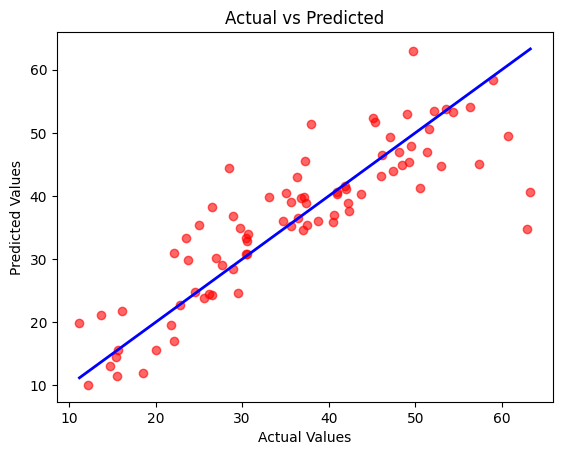

In [22]:
from sklearn.linear_model import Ridge
ridge=evaluate_model(Ridge(alpha=0.1))